МОСКОВСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНИЧЕСКИЙ УНИВЕРСИТЕТ
им. Н.Э. Баумана

Факультет “Информатика и системы управления”
Кафедра “Системы обработки информации и управления”

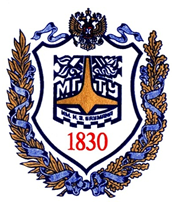

Дисциплина “Системное программирование”

Отчёт по лабораторной работе №5. Вариант №18
“Арифметические вычисления”

Выполнил:
Студент группы ИУ5-35Б
Сергучанов Т.Н.
Преподаватель:
Аксенова М.В
Артамонов Ю.Н.

Москва 2026


Задание:

2. Из заданного текстового файла (латиница) прочитать каждый k-й символ, результат записать во второй файл. Имена файлов, значение передавать параметрами командной строки.

3. Для заданного текстового файла (латиница) прочитать все строки (строка заканчивается символом разрыва строки 0x0a) и записать их во второй файл в обратном порядке: первая строка первого файла должна стать последней во втором и т.д. Имена файлов передавать параметрами командной строки.


## Код программы пункта 2.

In [ ]:
format ELF64

public _start

section '.data' writeable
    file1 db "a.txt", 0               """файл с текстом"""
    file2 db "b.txt", 0               """пустой файл"""

section '.bss' writeable
    b rb 1                            """выделяем один байт в оперативной памяти для считывания каждого k-го символа, чтобы в дальнейшем отправить его в файл b.txt"""

section '.text' executable
_start:
    cmp qword [rsp], 2                """проверка на передачу k-го символа как параметр командной строки"""
    jl exit_program

    mov rax, [rsp+16]
    movzx r15, byte [rax]             """записали ASCII-код символа в rax, после чего расшифровали и его значение записали в r15"""
    sub r15, 48

    mov rax, 2
    mov rdi, file1
    mov rsi, 0                        """открываем файл a.txt(с текстом) на чтение, проверяем на успешное открытие и запоминаем дескриптор файла в r12"""
    syscall
    cmp rax, 0
    jl exit_program
    mov r12, rax

    mov rax, 2
    mov rdi, file2
    mov rsi, 1
    mov rdx, 0                        """открываем файл b.txt на запись, проверяем на успешное открытие и запоминаем дескриптор файла в r14"""
    syscall
    cmp rax, 0
    jl close_file1
    mov r14, rax

    mov r13, 1                       """r13 - счётчик символов"""

processing_loop:                     """принцип работы цикла processing_loop: читаем один байт из a.txt в буфер (b), проверяем, всё ли мы считали из файла, """
    mov rax, 0      """если счётчик символов не равен k-му, прыгаем в skip_write, прибавляем на единицу и начинаем цикл processing_loop, благодаря чему предыдущий, неподходящий символ в буфере затирается следующим"""
    mov rdi, r12                     """если же условие сработало, мы записываем нужный символ в файл b.txt и обнуляем счётчик символов"""
    mov rsi, b
    mov rdx, 1
    syscall

    cmp rax, 0
    je close_all

    cmp r13, r15
    jne skip_write

    mov rax, 1
    mov rdi, r14
    mov rsi, b
    mov rdx, 1
    syscall

    mov r13, 0

skip_write:
    add r13, 1
    jmp processing_loop

close_all:                             """если rax стал равен нулю, значит мы считали весь файл a.txt. После этого прыгаем в блок закрытия файлов, а после - завершения программы"""
    close_file2:
        mov rax, 3
        mov rdi, r14
        syscall

    close_file1:
        mov rax, 3
        mov rdi, r12
        syscall

exit_program:
    mov rax, 60
    mov rdi, 0
    syscall


## Скриншоты работы программы пункта 2.

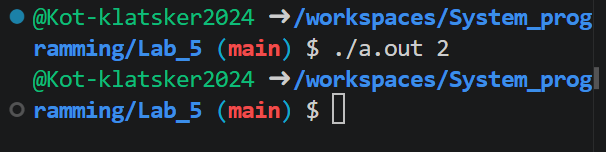

capture_20261109190811803.bmp

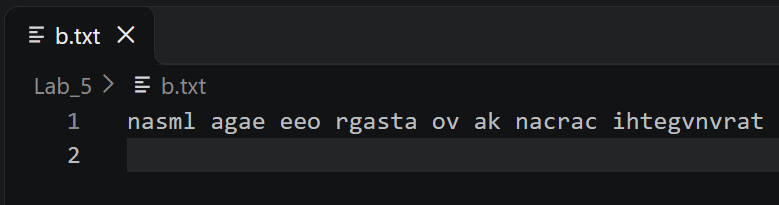

## Код программы пункта 3.

In [ ]:
format ELF64

public _start

section '.bss' writeable
    b rb 4095                                 """выделяем буфер с запасом для файла с текстом (c.txt)"""

section '.text' executable
_start:
    cmp qword [rsp], 3                        """проверка на передачу названия файла с текстом и пустого файла (d.txt)"""
    jl exit_program

    mov r15, [rsp+16] ; file1                 """c.txt"""
    mov r14, [rsp+24] ; file2                 """d.txt"""

    mov rax, 2
    mov rdi, r15                              """открываем файл c.txt на чтение, проверяем на успешное открытие и запоминаем дескриптор файла в r13"""
    mov rsi, 0
    mov rdx, 0
    syscall

    cmp rax, 0
    jl exit_program

    mov r13, rax

    mov rax, 2
    mov rdi, r14                              """открываем файл d.txt на чтение, проверяем на успешное открытие и запоминаем дескриптор файла в r12"""
    mov rsi, 1
    mov rdx, 0
    syscall

    cmp rax, 0
    jl exit_program

    mov r12, rax

    record_file1_in_bufer:                    """записываем весь c.txt в буфер (b)"""
        mov rax, 0
        mov rdi, r13
        mov rsi, b
        mov rdx, 4095
        syscall

        cmp rax, 0
        jle close_files                       """проверяем на корректную отправку. При правильно работе в rax будет передано количество прочитанных байт """
        mov rbx, rax

        mov rsi, b
        add rsi, rbx                          """rsi - указывает на символ перед символом переноса строки последней строчки(предпоследний символ последней строки)."""
        mov rcx, rsi                          """rcx - указывает на последний символ последней строки (символ переноса строки последней строчки)"""
        sub rcx, 1
        sub rsi, 2

    find_end_str_in_file1:                     """идём по буферу от конца к началу"""
        cmp byte [rsi], 0x0A                   """если rsi указывает на конец строки, значит мы прочитали всю строчку и дошли до места между началом текущей строчки и концом следующей строки"""
        je calculate_lenght1                   """прыгаем в calculate_lenght1 и записываем текущую строку в файл d.txt"""
        cmp rsi, b                             """если rsi указывает на начало буфера, значит мы дошли до начала самой верхней, первой, строки."""
        je calculate_lenght2                   """прыгаем в calculate_lenght2 и записываем в d.txt последнюю, верхнюю в буфере, строчку"""

        sub rsi, 1
        jmp find_end_str_in_file1

    calculate_lenght1:
        mov rdx, rcx                           """вычисляем длину строки и записываем в rdx: конец строки - начало строки"""
        sub rdx, rsi
        add rsi, 1                             """прибавляем к rsi единицу, чтобы он указывал на первый символ текущей строки"""
        jmp record_bufer_in_file2

    calculate_lenght2:
        mov rdx, rcx                           """аналогичное вычисление длины строки"""
        sub rdx, rsi

    record_bufer_in_file2:
        mov rax, 1
        mov rdi, r12
        syscall

        cmp rsi, b
        je close_files                  """rsi при системном вызове не затирается, поэтому мы можем прописать условия: если он указывает на начало буфера, значит мы считали весь буфер, закрываем файлы"""

        sub rsi, 1                      """если же в буфере ещё есть данные, мы указываем rsi на перенос следующей строки, присваиваем его rcx и ещё раз сдвигаем  rsi на единицу, указывая его на последнюю букву строки"""
        mov rcx, rsi
        sub rsi, 1
        jmp find_end_str_in_file1

    close_files:
        close_file1:
            mov rax, 3                  """закрываем файлы и завершаем программу"""
            mov rdi, r13
            syscall
        close_file2:
            mov rax, 3
            mov rdi, r12
            syscall

    exit_program:
        mov rax, 60
        mov rdi, 0
        syscall


## Скриншоты работы программы пункта 3.
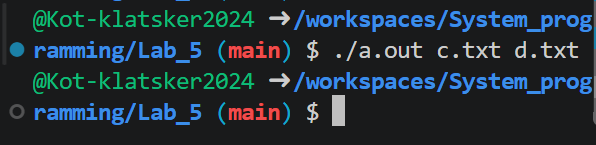

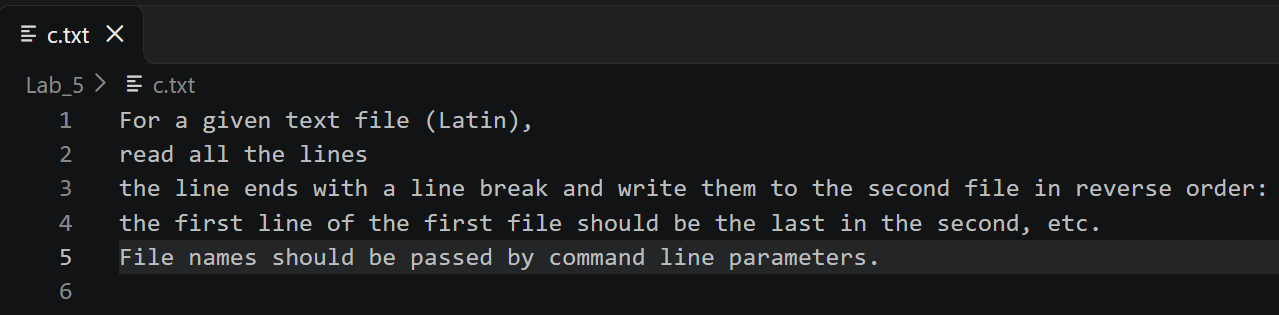

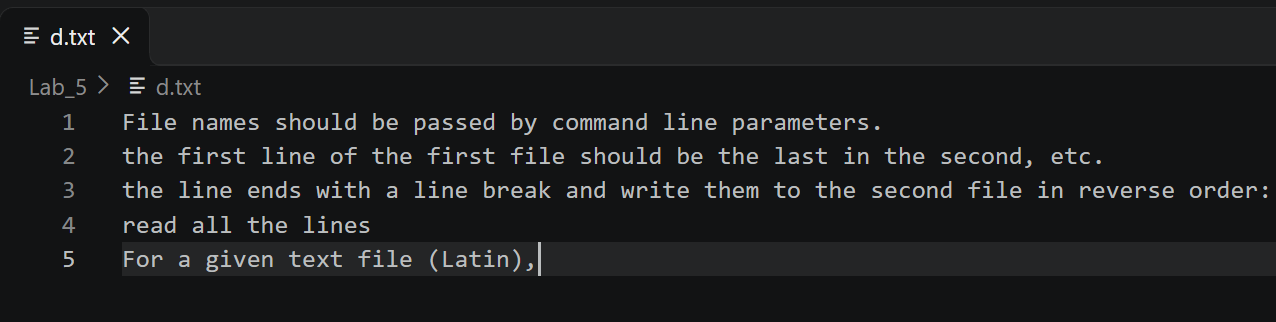